# Mini-Project 1: Weather forecast with Python web APIs

The reusable `WeatherForecastClient` in `src/weather_client.py` handles HTTP requests, retries, geocoding, forecast retrieval, and parsing. This notebook keeps configuration, API comparison, candidate selection, demonstrations, visualisation, and the report. Run from the project folder so the offline JSON fixtures in `samples/` are available.

**Before using MET Norway:** replace the clearly marked email placeholder in the configuration cell with your own university email. The notebook does not invent or send a made-up contact address. The city and candidate index are also changed only in that cell. The online demonstration is best-effort; saved parsing checks work offline.

This notebook makes a small number of live requests when run. Do not repeatedly run all cells; use the cached result in memory and respect each provider's traffic and caching guidance.

In [1]:

LOCATION = 'Dresden'
CONTACT_EMAIL = 'B38635@students.ucu.ac.ug'
LOCATION_CANDIDATE_INDEX = 1  # 1-based; change this after reviewing ambiguous candidates.

In [2]:
import json
import os
from typing import Any

import matplotlib.pyplot as plt
import requests

from src.weather_client import WeatherForecastClient, WeatherRequestError

FORECAST_DAYS = 7
client = WeatherForecastClient(contact_email=CONTACT_EMAIL)


## Part A — HTTP fundamentals

The reusable client in `src/weather_client.py` provides both HTTP paths; the next two cells request the same geocoding result, once with `urllib` and once with `requests`. Both paths set a timeout, use the shared retry cap, and return the response status, content type, and measured elapsed time. The Requests result is cached for the later `geocode` call to avoid another request.

In [3]:
geocoding_params = {
    'name': LOCATION,
    'count': 10,
    'language': 'en',
    'format': 'json',
}
urllib_payload = None
try:
    urllib_payload, urllib_metadata = client.request_json_urllib(
        client.GEOCODING_URL, geocoding_params, timeout=8.0, retries=1
    )
    print('urllib status:', urllib_metadata['status_code'])
    print('urllib Content-Type:', urllib_metadata['content_type'])
    print(f"urllib response time: {urllib_metadata['response_time_seconds']:.3f} s")
except WeatherRequestError as error:
    print('urllib geocoding unavailable:', error)


urllib status: 200
urllib Content-Type: application/json; charset=utf-8
urllib response time: 1.205 s


In [4]:
requests_payload = None
try:
    requests_payload, requests_metadata = client.get_geocoding_payload(LOCATION)
    print('requests status:', requests_metadata['status_code'])
    print('requests Content-Type:', requests_metadata['content_type'])
    print(f"requests response time: {requests_metadata['response_time_seconds']:.3f} s")
except WeatherRequestError as error:
    print('requests geocoding unavailable:', error)


requests status: 200
requests Content-Type: application/json; charset=utf-8
requests response time: 0.963 s


### Comparison

`urllib` is part of Python, so it needs no extra package, but the caller manually assembles the encoded URL, creates a `Request` for headers, reads and decodes bytes, handles HTTP errors, and parses JSON. The `WeatherForecastClient` keeps that repetitive plumbing in one reusable class while leaving the protocol details visible for comparison. `requests` is shorter: passing `params=` handles query encoding, a `headers` mapping controls the User-Agent, `timeout` bounds waiting, `raise_for_status()` provides explicit HTTP failure handling, and `.json()` decodes the body. The client applies a shared retry cap and raises a custom exception after final failure; requests and urllib do not retry on their own here. The urllib method constructs a URL using `urllib.parse.urlencode`; the Requests method passes the original parameter mapping and lets Requests encode it. The recorded metadata is from the actual Requests call and varies by run.

In [5]:
# Offline parsing checks use saved fixtures and do not make API requests.
with open(os.path.join('samples', 'geocoding_sample.json'), encoding='utf-8') as file:
    sample_geocoding = json.load(file)
with open(os.path.join('samples', 'forecast_sample.json'), encoding='utf-8') as file:
    sample_forecast = json.load(file)

assert WeatherForecastClient.parse_candidates({}) == []
assert len(WeatherForecastClient.parse_candidates(sample_geocoding)) == 1
assert WeatherForecastClient.parse_candidates(sample_geocoding)[0]['name'] == 'Dresden'
assert WeatherForecastClient.parse_candidates({'results': [{'name': 'bad'}]}) == []
print('Geocoding fixture checks passed.')

def choose_location(candidates: list[dict[str, Any]], choice: int) -> dict[str, Any] | None:
    """Print ambiguous candidates and return the configured 1-based selection."""
    if not candidates:
        print('No matching locations were returned. Try a more specific place name.')
        return None
    if len(candidates) > 1:
        print('Ambiguous location; candidates (edit LOCATION_CANDIDATE_INDEX to choose):')
        for number, candidate in enumerate(candidates, start=1):
            print(
                f"{number}. {candidate['name']}, "
                f"{candidate.get('admin1', '')}, {candidate.get('country', '')} "
                f"({candidate['latitude']}, {candidate['longitude']})"
            )
    if choice < 1 or choice > len(candidates):
        raise ValueError(f'Candidate index must be between 1 and {len(candidates)}.')
    return candidates[choice - 1]


Geocoding fixture checks passed.


In [6]:
sample_frame = WeatherForecastClient.parse_forecast(sample_forecast)
assert len(sample_frame) == 3
assert sample_frame.loc[0, 'Max temperature (°C)'] == 15.4
assert sample_frame.loc[1, 'Weather'] == 'Slight rain'
assert WeatherForecastClient.weather_description(987) == 'Unknown weather code (987)'
try:
    WeatherForecastClient.parse_forecast({'daily': {'time': ['2026-10-12']}})
except ValueError:
    pass
else:
    raise AssertionError('Missing forecast fields must be rejected.')
print('Forecast fixture checks passed (9 assert-based checks total).')


Forecast fixture checks passed (9 assert-based checks total).


## Part B — retrieve and display a forecast

The client parser handles a missing `results` key as an empty list. For multiple matches, the notebook prints each candidate and chooses the configured 1-based `LOCATION_CANDIDATE_INDEX`, so Restart & Run All does not pause for interactive input. The forecast query requests daily high and low temperature, precipitation sum, maximum wind speed, and the WMO weather code. `timezone=auto` makes the date labels local to the coordinates.

In [7]:
selected_location = None
try:
    location_candidates = client.geocode(LOCATION)
    selected_location = choose_location(
        location_candidates, LOCATION_CANDIDATE_INDEX
    )
    if selected_location is not None:
        print(
            'Selected:', selected_location['name'],
            selected_location.get('admin1', ''),
            selected_location.get('country', ''),
        )
except WeatherRequestError as error:
    print('Could not geocode the configured location:', error)


Ambiguous location; candidates (edit LOCATION_CANDIDATE_INDEX to choose):
1. Dresden, Saxony, Germany (51.05089, 13.73832)
2. Dresden, Tennessee, United States (36.29145, -88.70811)
3. Dresden, Ohio, United States (40.12146, -82.01069)
4. Dresden, New York, United States (42.68396, -76.9558)
5. Dresden, Kansas, United States (39.62417, -100.42236)
6. Dresden, Georgia, United States (33.35151, -84.91855)
7. Dresden, Missouri, United States (38.75113, -93.33493)
8. Dresden, North Carolina, United States (36.45818, -81.54566)
9. Dresden, Texas, United States (32.03071, -96.68055)
10. Dresden, Iowa, United States (42.97914, -92.31851)
Selected: Dresden Saxony Germany


Forecast HTTP 200 from Europe/Berlin; response time 1.100 s.
For Dresden: 2026-10-12 to 2026-10-18, daily high 11.2 to 19.1 °C, total forecast precipitation 4.9 mm.
Source: Weather data by Open-Meteo.com: https://open-meteo.com/
Date (local)  Max temperature (°C)  Min temperature (°C)  Precipitation (mm)  Max wind speed (km/h)  WMO weather code             Weather
  2026-10-12                  12.6                   8.1                0.80                   10.5                80 Slight rain showers
  2026-10-13                  16.5                   4.8                0.60                    7.2                61         Slight rain
  2026-10-14                  15.4                   9.4                2.05                   16.4                80 Slight rain showers
  2026-10-15                  15.9                   5.0                0.00                    4.2                45                 Fog
  2026-10-16                  19.1                   6.2                0.00     

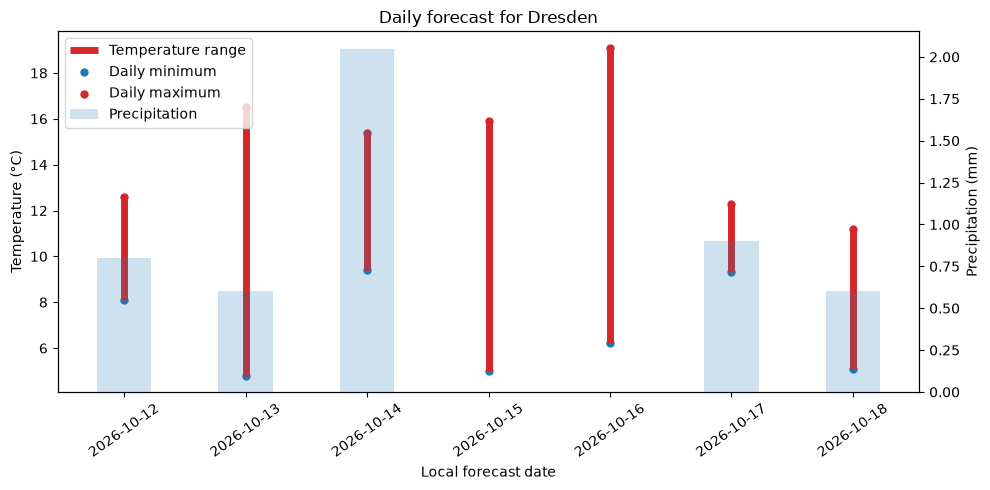

In [8]:
forecast_frame = None
if selected_location is None:
    print('Forecast skipped because no location was selected.')
else:
    try:
        forecast_payload, forecast_metadata = client.get_forecast(
            selected_location['latitude'],
            selected_location['longitude'],
            FORECAST_DAYS,
        )
        forecast_frame = WeatherForecastClient.parse_forecast(forecast_payload)
        print(
            f"Forecast HTTP {forecast_metadata['status_code']} from "
            f"{forecast_payload.get('timezone', 'local timezone')}; "
            f"response time {forecast_metadata['response_time_seconds']:.3f} s."
        )
        print(
            f"For {selected_location['name']}: "
            f"{forecast_frame['Date (local)'].min().date()} to "
            f"{forecast_frame['Date (local)'].max().date()}, "
            f"daily high {forecast_frame['Max temperature (°C)'].min():.1f} to "
            f"{forecast_frame['Max temperature (°C)'].max():.1f} °C, "
            f"total forecast precipitation "
            f"{forecast_frame['Precipitation (mm)'].sum():.1f} mm."
        )
        print('Source: Weather data by Open-Meteo.com: https://open-meteo.com/')
        print(forecast_frame.to_string(index=False))
    except WeatherRequestError as error:
        print('Forecast request failed:', error)
    except ValueError as error:
        print('Forecast response could not be parsed:', error)

if forecast_frame is not None and not forecast_frame.empty:
    dates = forecast_frame['Date (local)']
    low = forecast_frame['Min temperature (°C)']
    high = forecast_frame['Max temperature (°C)']
    fig, temperature_axis = plt.subplots(figsize=(10, 5))
    temperature_axis.vlines(dates, low, high, color='tab:red', linewidth=5, label='Temperature range')
    temperature_axis.scatter(dates, low, color='tab:blue', s=25, label='Daily minimum')
    temperature_axis.scatter(dates, high, color='tab:red', s=25, label='Daily maximum')
    temperature_axis.set_ylabel('Temperature (°C)')
    temperature_axis.set_xlabel('Local forecast date')
    temperature_axis.tick_params(axis='x', rotation=35)
    precipitation_axis = temperature_axis.twinx()
    precipitation_axis.bar(
        dates, forecast_frame['Precipitation (mm)'],
        width=0.45, color='tab:blue', alpha=0.22, label='Precipitation',
    )
    precipitation_axis.set_ylabel('Precipitation (mm)')
    handles_a, labels_a = temperature_axis.get_legend_handles_labels()
    handles_b, labels_b = precipitation_axis.get_legend_handles_labels()
    temperature_axis.legend(handles_a + handles_b, labels_a + labels_b, loc='upper left')
    temperature_axis.set_title(f"Daily forecast for {selected_location['name']}")
    fig.tight_layout()
    plt.show()
else:
    print('Table and chart are unavailable without a valid live forecast.')


## Part C — robustness and second source

The checks below exercise an unknown place, an out-of-range latitude, a simulated offline transport, and a very small timeout. Invalid input and ordinary HTTP 4xx responses fail immediately; connection errors and server-side 5xx responses are retried up to two times with exponential backoff. Each final failure has a provider/URL context in `WeatherRequestError`. The simulated outage uses an injected callable and sends no network traffic.

In [9]:
# Deliberately invalid city: a successful API response with no results is expected.
try:
    invalid_candidates = client.geocode('zz-no-such-weather-place-zz')
    if invalid_candidates:
        print('The provider unexpectedly matched the invalid city input.')
    else:
        print('Invalid city handled: no candidates; no forecast is requested.')
except WeatherRequestError as error:
    print('Invalid-city demonstration could not reach geocoding:', error)

# Deliberately invalid latitude demonstrates the API's client-error response.
try:
    client.get_forecast(999.0, 0.0, 1)
    print('Invalid latitude was not rejected by the forecast API.')
except WeatherRequestError as error:
    print('Invalid latitude handled:', error)

def simulated_offline(
    url: str,
    params: dict[str, Any],
    timeout: float,
    headers: dict[str, str],
) -> requests.Response:
    """Transport stub that deterministically simulates a disconnected network."""
    raise requests.ConnectionError('simulated offline mode')

offline_client = WeatherForecastClient(
    max_retries=2, backoff_seconds=0, requester=simulated_offline
)
try:
    offline_client.request_json(client.FORECAST_URL, {})
except WeatherRequestError as error:
    print('Simulated no-network failure handled:', error)

# A microsecond timeout is intentionally likely to fail, but cannot stop the notebook.
probe_latitude = selected_location['latitude'] if selected_location else 51.05
try:
    client.request_json(
        client.FORECAST_URL,
        {
            'latitude': probe_latitude,
            'longitude': 13.74,
            'daily': 'temperature_2m_max',
            'forecast_days': 1,
            'timezone': 'auto',
        },
        timeout=0.000001,
        retries=1,
    )
    print('Tiny-timeout demonstration completed before the deadline.')
except WeatherRequestError as error:
    print('Tiny timeout handled:', error)


Invalid city handled: no candidates; no forecast is requested.
Invalid latitude handled: HTTP request to https://api.open-meteo.com/v1/forecast failed with status 400: 400 Client Error: Bad Request for url: https://api.open-meteo.com/v1/forecast?latitude=999.0&longitude=0.0&daily=temperature_2m_max%2Ctemperature_2m_min%2Cprecipitation_sum%2Cwind_speed_10m_max%2Cweather_code&forecast_days=1&timezone=auto
Simulated no-network failure handled: GET https://api.open-meteo.com/v1/forecast failed after 3 attempt(s): simulated offline mode
Tiny timeout handled: GET https://api.open-meteo.com/v1/forecast failed after 2 attempt(s): HTTPSConnectionPool(host='api.open-meteo.com', port=443): Max retries exceeded with url: /v1/forecast?latitude=51.05089&longitude=13.74&daily=temperature_2m_max&forecast_days=1&timezone=auto (Caused by ConnectTimeoutError(<HTTPSConnection(host='api.open-meteo.com', port=443) at 0x233b3161090>, 'Connection to api.open-meteo.com timed out. (connect timeout=1e-06)'))


In [10]:
if selected_location is None:
    print('MET Norway comparison skipped because geocoding did not select a place.')
elif not client.contact_email or client.contact_email == 'YOUR_UNIVERSITY_EMAIL':
    print('MET Norway comparison skipped until the real university email is configured.')
else:
    try:
        met_payload, met_metadata = client.get_met_norway_forecast(
            selected_location['latitude'], selected_location['longitude']
        )
        time_series = met_payload.get('properties', {}).get('timeseries', [])
        if not time_series:
            print('MET Norway returned no time-series entries.')
        else:
            first = time_series[0]
            details = first['data']['instant']['details']
            print(
                f"MET Norway HTTP {met_metadata['status_code']} at "
                f"{first.get('time', 'unknown time')}: "
                f"{details.get('air_temperature', 'unavailable')} °C "
                f"(air temperature; instantaneous, not daily maximum/minimum)."
            )
            print('Source: Data from MET Norway: https://api.met.no/weatherapi/locationforecast/2.0/')
            if met_metadata['status_code'] == 203:
                print('Warning: MET Norway status 203 indicates a deprecated or beta product.')
    except (WeatherRequestError, ValueError, KeyError) as error:
        print('MET Norway comparison unavailable:', error)


MET Norway HTTP 200 at 2026-10-12T06:00:00Z: 8.7 °C (air temperature; instantaneous, not daily maximum/minimum).
Source: Data from MET Norway: https://api.met.no/weatherapi/locationforecast/2.0/


## Part D — report

### Data flow and design

The client class in `src/weather_client.py` owns reusable transport, retry, caching, geocoding, forecast, and parsing behavior. The notebook wires it to a configured place, presents candidates, and renders the results. Its path is:

```text
Configuration (place + contact)
    -> Open-Meteo Geocoding API
    -> candidate list / configured selection
    -> latitude and longitude
    -> Open-Meteo Forecast API (timezone=auto)
    -> validated daily JSON arrays
    -> pandas table + text summary + temperature/precipitation chart
```

Part A makes one geocoding request with `urllib` and repeats it with `requests`, using `urlencode` in the first case and `params=` in the second. It records the real HTTP status, `Content-Type`, and elapsed time rather than assuming a response will be successful. The Requests JSON is cached for the later geocoding function. Geocoding can return no `results` property, so the parser treats an omitted key as an empty candidate list. With multiple candidates the notebook prints identifying fields and applies the 1-based index in the configuration cell. This avoids an `input()` pause that would make Restart & Run All non-reproducible.

The forecast call selects daily maximum and minimum two-metre air temperature, precipitation total, maximum ten-metre wind speed, and a WMO code. Open-Meteo returns parallel daily arrays and a timezone. The parser verifies required fields and equal array lengths before constructing a DataFrame. Column names state their units, the dates are explicitly parsed, and WMO codes are mapped to human-readable descriptions with an unknown-code fallback. The table summary reports the returned date range, high-temperature span, and total precipitation. A temperature range is plotted for each local day while precipitation is shown on a second axis. The primary displayed source is labelled and linked to Open-Meteo. Fixture-based assertions cover empty and malformed geocoding, parsed coordinates/name, forecast length and values, WMO decoding, unknown codes, and missing forecast fields; these checks need no network.

### API terms, licensing, and product implications

Open-Meteo documents its API data under the Creative Commons Attribution 4.0 International licence (CC BY 4.0). CC BY allows redistribution and adaptation, but requires appropriate credit, a link to the licence, and an indication of modifications; attribution must not imply endorsement. Open-Meteo specifically asks for a link beside displayed weather data. This notebook labels the source in its output and its data are transformed into a table and chart, so a deployed application should retain a visible attribution near both. Its Geocoding API uses the GeoNames database; GeoNames also requires attribution under CC BY 4.0, so a product should credit that place-name source as well as Open-Meteo. The API service terms are separate from the data licence: the free endpoint is for non-commercial use and imposes request-rate limits; websites or apps with advertising or subscriptions, and commercial-product integrations, require a paid plan or other permission. The Terms of Use disclaim guarantees about accuracy, completeness, availability, and uninterrupted service. A real product must verify the current terms, select a plan compatible with its commercial status and volume, budget for outages, and avoid representing forecast data as guaranteed. Open-Meteo API terms, licence, and [Geocoding API documentation](https://open-meteo.com/en/docs/geocoding-api); GeoNames [data and attribution](https://www.geonames.org/about.html).

MET Norway states that, unless a product says otherwise, its data are available under both the Norwegian Licence for Open Government Data 2.0 and CC BY 4.0. Credit should identify The Norwegian Meteorological Institute, shortened to MET Norway, and link to the data source; the MET result is labelled that way in the comparison cell. The API additionally requires an identifying User-Agent with application identity and contact information, discourages unnecessary traffic, asks clients to honor caching headers, and limits coordinates to at most four decimals. Its terms state that there is no delivery guarantee or SLA, and a 203 status signals a deprecated or beta product that merits warning. Commercial use should be evaluated against the provider's applicable licence and any product-specific terms rather than assumed from the word open. A production client needs a real maintained contact, cache policy, rate control, source attribution, and a plan for provider changes. MET Norway terms and licensing: [Terms of Service](https://api.met.no/doc/TermsOfService) and [Licensing and Data Policy](https://api.met.no/doc/License).

### Reliability and failure handling

An HTTP request can fail before a response arrives, return a non-success status, or return an unusable payload. Both HTTP implementations set timeouts, inspect status, and raise the same clear custom exception after bounded attempts. Network exceptions and server-side 5xx responses use at most two retries after the initial attempt, with delays of 0.5 and 1.0 seconds. Client errors such as invalid coordinates are not retried because repeating a bad request cannot repair it. Invalid JSON and inconsistent daily arrays are reported as parsing failures, not silently represented as a successful empty forecast. The deliberately broken examples exercise a zero-match city, latitude 999, an injected connection failure, and an extremely short timeout; exception handling keeps expected demonstration failures from aborting the rest of the notebook. The provider may be unreachable during a full run, so the live forecast and chart are explicitly skipped if no valid response is available, while the offline parsing assertions remain runnable.

These controls address delay, transient network conditions, and malformed data, but do not make forecasts certain. Retry caps prevent an assignment notebook from generating excessive traffic. MET requests round coordinates to four decimal places. For production, response caching should also honor each provider's cache headers or expiry guidance; a service should not poll merely because it can. Provider product IDs, response schemas, and model output can change, so parsing should be monitored and updated. A forecast is an estimate, not an observation or safety guarantee; consequential decisions need authoritative, current warnings and suitable independent controls.

### Privacy implications

The location string is sent to Open-Meteo's geocoding service; the selected latitude and longitude are then sent to the forecast providers. Those calls disclose the location to third parties and may be accompanied by the notebook runner's IP address and request metadata. MET Norway specifically says logs can include IP addresses and coordinates, and recommends a proxy gateway where anonymity is required. Open-Meteo's free service terms likewise describe technical logging and retention. A city-level query is less precise than device GPS, but it can still expose a home, workplace, trip, or other sensitive place, especially when combined with account or timing data. This notebook requests no name, account ID, or secrets, and its example uses only a city. A real application should explain this disclosure, request only the precision needed, avoid sending precise coordinates without a clear purpose, minimize log retention, and avoid exposing a user's exact location in public output. If an application needs to conceal client IPs or centralize caching and identification, a controlled backend proxy can make the provider request, though the application operator then assumes responsibility for handling the location data it receives.